# CSE 5526 — Programming Assignment #1 (PA1)

**STUDENT INSTRUCTION NOTEBOOK**

---

⚠️ **IMPORTANT**
- You may ONLY modify code blocks marked with **`TODO`**
- Do **NOT** change function names, inputs, outputs, or print/plot formats
- Your notebook **must be run before submission**
- Follow the specifications exactly

---

### What you are building

A three-layer network (64 → 32 → 16 → 10) trained from scratch with per-sample SGD on the
8×8 handwritten digits dataset, evaluated with 5-fold stratified cross-validation.

You implement two output layers: **sigmoid with scaled sum-of-squared-error** (parts 1–3) and
**softmax with cross-entropy** (part 4). Both share the same hidden layers and the same training
loop — only the output activation and the output-layer error term differ.

### Map of this notebook

| Section | Assignment part | Contents |
|---|---|---|
| 0 | — | Configuration and data loading — given |
| 1 | — | Activations and cost functions — **TODO** |
| 2 | — | `ThreeLayerNN` — **TODO** |
| 3 | 2 | Learning rate schedules — **TODO** |
| 4 | — | `train_fold` — **TODO** |
| 5 | — | Cross-validation driver, plotting, summary — given |
| 6 | 1, 2 | Five strategies with the sigmoid output |
| 7 | 3 | Model evaluation and test set — **TODO** |
| 8 | 4 | Softmax with cross-entropy — **TODO** |
| 9 | 1–4 | Written discussion — **TODO** |

Expect the full notebook to take several minutes to run.

In [1]:
# ============================================================
# Imports (DO NOT MODIFY)
# ============================================================
import warnings

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
# ============================================================
# Configuration (DO NOT MODIFY)
# ============================================================
SEED        = 42
N_CLASSES   = 10
LAYER_SIZES = (64, 32, 16, 10)
EPOCHS      = 100
N_FOLDS     = 5

# Part 1: fixed learning rates
FIXED_LRS   = [0.01, 0.05, 0.25]

# Part 2: schedule hyperparameters (given)
POWER_ETA0, POWER_C, POWER_S = 0.10, 1.0, 11500
EXP_ETA0,   EXP_S            = 0.10, 57500

np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7, 4)

In [3]:
# ============================================================
# Data Loading and Preprocessing (DO NOT MODIFY)
# ============================================================
# The test set is split off once here and must not be touched again until the
# final evaluation at the end of the notebook. Everything in between - training,
# validation, model selection - uses only X_pool / y_pool.
digits = load_digits()
X = digits.data.astype(np.float64) / 16.0     # pixel intensities are 0..16
y = digits.target.astype(int)

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
pool_idx, test_idx = next(splitter.split(X, y))
X_pool, y_pool = X[pool_idx], y[pool_idx]
X_test, y_test = X[test_idx], y[test_idx]


def one_hot(labels, num_classes=N_CLASSES):
    out = np.zeros((labels.shape[0], num_classes), dtype=np.float64)
    out[np.arange(labels.shape[0]), labels] = 1.0
    return out


def nanmean(a, axis=None):
    # A diverged fold records NaN for its remaining epochs; NaN is the right
    # answer for those, so the all-NaN warning is silenced rather than avoided.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        return np.nanmean(a, axis=axis)


def nanstd(a, axis=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        return np.nanstd(a, axis=axis)


print(f"CV pool : {X_pool.shape[0]} samples, {X_pool.shape[1]} features")
print(f"Test    : {X_test.shape[0]} samples (held out)")
print(f"Classes : {N_CLASSES}, class counts in pool: {np.bincount(y_pool)}")

CV pool : 1437 samples, 64 features
Test    : 360 samples (held out)
Classes : 10, class counts in pool: [142 146 142 146 145 145 145 143 139 144]


## 1. Activation and cost functions

$$J_{\text{SSE}} = \frac{1}{N}\sum_{i=1}^{N}\frac{1}{2}\sum_{k=1}^{10}\left(d_{ik}-y_{ik}\right)^2
\qquad
J_{\text{CE}} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{10} d_{ik}\log y_{ik}$$

where $d_{ik}$ is the desired output and $y_{ik}$ the network output for sample $i$, neuron $k$.
Both costs are averaged over samples, as specified in the assignment. Each returns a single float.

Three numerical points worth handling now rather than debugging later:

- `sigmoid` overflows for large negative induced local fields $v$. Clip the argument.
- `softmax` overflows for large positive $v$. Subtract the row maximum before exponentiating —
  this does not change the result.
- `cost_ce` takes the log of a probability that can underflow to exactly 0. Clip it away from zero.

In [4]:
# ============================================================
# Activation Functions and Costs (TODO)
# ============================================================
# TODO: implement ReLU and its derivative
def relu(v):
    return np.maximum(0.0, v)


def relu_deriv(v):
    return (v > 0).astype(np.float64)


# TODO: implement the sigmoid function (numerically stable)
def sigmoid(v):
    return 1.0 / (1.0 + np.exp(-np.clip(v, -500.0, 500.0)))


# TODO: implement the softmax function (numerically stable, row-wise)
def softmax(v):
    e = np.exp(v - np.max(v, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)


# TODO: implement the scaled sum-of-squared-error cost
#       mean over samples of 0.5 * sum_k (d - y)^2
#       Returns: a single float
def cost_sse(y_out, D):
    return float(np.mean(0.5 * np.sum((D - y_out) ** 2, axis=1)))


# TODO: implement the cross-entropy cost
#       mean over samples of -sum_k d * log(y)
#       Returns: a single float
def cost_ce(y_out, D):
    return float(np.mean(-np.sum(D * np.log(np.clip(y_out, 1e-12, 1.0)), axis=1)))


# (DO NOT MODIFY) Dispatch table used by the training loop
COST_FN = {"sigmoid_sse": cost_sse, "softmax_ce": cost_ce}

## 2. The network

One class supports both output layers, selected by `mode`:

| `mode` | output activation | cost |
|---|---|---|
| `"sigmoid_sse"` | sigmoid | scaled sum of squared error |
| `"softmax_ce"` | softmax | cross-entropy |

The output-layer error term $\partial J/\partial v_k$ differs between the two. Part 3(a) of the
assignment asks you to derive it for the softmax case — do that derivation before you write the
code, and use your own result here.

**Initialization.** Draw the weights of each layer from $U(-a, a)$ with
$a = \sqrt{6/(n_{\text{in}} + n_{\text{out}})}$, and set all biases to zero.

**Shapes.** `forward` is called with a single sample of shape `(1, 64)` during training and with a
full matrix of shape `(N, 64)` during evaluation. Write it so both work — no Python loops over
samples inside `forward`.

`get_weights` and `set_weights` are provided. The training loop uses them to snapshot weights, so
do not change how they work.

In [5]:
# ============================================================
# Three-Layer Neural Network (TODO)
# ============================================================
class ThreeLayerNN:
    def __init__(self, sizes=LAYER_SIZES, mode="sigmoid_sse", seed=0):
        assert mode in ("sigmoid_sse", "softmax_ce")
        self.mode = mode
        rng = np.random.default_rng(seed)
        # TODO: initialize self.W (list of 3 weight matrices) and self.b (list of
        #       3 bias row-vectors). Weights ~ U(-a, a) with a = sqrt(6/(n_in+n_out));
        #       biases all zero. Shapes: W[i] is (sizes[i], sizes[i+1]),
        #       b[i] is (1, sizes[i+1]).
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            a = np.sqrt(6.0 / (n_in + n_out))
            self.W.append(rng.uniform(-a, a, size=(n_in, n_out)))
            self.b.append(np.zeros((1, n_out)))

    def forward(self, x):
        # TODO: implement forward propagation.
        #       Hidden layers use ReLU. The output layer uses sigmoid when
        #       self.mode == "sigmoid_sse" and softmax when "softmax_ce".
        # Returns: (y3, cache) where y3 is the network output of shape (N, 10)
        #          and cache holds whatever backward() needs.
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            v1 = x @ self.W[0] + self.b[0]
            y1 = relu(v1)
            v2 = y1 @ self.W[1] + self.b[1]
            y2 = relu(v2)
            v3 = y2 @ self.W[2] + self.b[2]
            y3 = sigmoid(v3) if self.mode == "sigmoid_sse" else softmax(v3)
        cache = (x, v1, y1, v2, y2, y3)
        return y3, cache

    def backward(self, cache, D):
        # TODO: implement backpropagation.
        #       The output delta depends on self.mode. Derive it (Part 3(a)) rather
        #       than guessing; the two modes do not share the same expression.
        # Returns: (gW, gb), each a list of 3 arrays matching the shapes of
        #          self.W and self.b.
        x, v1, y1, v2, y2, y3 = cache
        N = x.shape[0]

        # Output error term dJ/dv3 (averaged over the N samples in the batch)
        if self.mode == "sigmoid_sse":
            delta3 = (y3 - D) * y3 * (1.0 - y3) / N
        else:  # softmax_ce
            delta3 = (y3 - D) / N

        delta2 = (delta3 @ self.W[2].T) * relu_deriv(v2)
        delta1 = (delta2 @ self.W[1].T) * relu_deriv(v1)

        gW = [x.T @ delta1, y1.T @ delta2, y2.T @ delta3]
        gb = [np.sum(delta1, axis=0, keepdims=True),
              np.sum(delta2, axis=0, keepdims=True),
              np.sum(delta3, axis=0, keepdims=True)]
        return gW, gb

    def sgd_step(self, gW, gb, eta):
        # TODO: update self.W and self.b in place using the gradients and
        #       learning rate eta.
        for i in range(len(self.W)):
            self.W[i] -= eta * gW[i]
            self.b[i] -= eta * gb[i]

    def predict(self, X):
        # TODO: return predicted class labels, shape (N,)
        y3, _ = self.forward(X)
        return np.argmax(y3, axis=1)

    # ---- provided (DO NOT MODIFY) ----
    def get_weights(self):
        return ([w.copy() for w in self.W], [b.copy() for b in self.b])

    def set_weights(self, snap):
        self.W = [w.copy() for w in snap[0]]
        self.b = [b.copy() for b in snap[1]]

## 3. Learning-rate schedules

$n$ is the number of **weight updates**, not the number of epochs. With 1150 training samples per
fold and per-sample SGD, one epoch is 1150 updates.

$$\eta_{\text{power}}(n) = \frac{\eta_0}{\left(1 + n/s\right)^{c}}
\qquad
\eta_{\text{exp}}(n) = \eta_0 \cdot 0.1^{\,n/s}$$

`lr_fixed` is a factory: it takes a learning rate and returns a function of `n`, so that all three
schedules have the same interface and the training loop can call `lr_fn(n)` without knowing which
one it has.

The last cell in this section prints $\eta$ at several values of $n$. Part 2 of the assignment
asks you to report these values.

In [6]:
# ============================================================
# Learning Rate Schedules (TODO)
# ============================================================
# TODO: return a function of n that always gives the same learning rate
def lr_fixed(eta):
    def fn(n):
        return eta
    return fn


# TODO: implement power scheduling using POWER_ETA0, POWER_C, POWER_S
def lr_power(n):
    return POWER_ETA0 / (1.0 + n / POWER_S) ** POWER_C


# TODO: implement exponential scheduling using EXP_ETA0, EXP_S
def lr_exponential(n):
    return EXP_ETA0 * 0.1 ** (n / EXP_S)

In [7]:
# ============================================================
# Schedule sanity check (DO NOT MODIFY)
# ============================================================
STRATEGIES = [(f"Fixed eta={eta}", lr_fixed(eta)) for eta in FIXED_LRS] + [
    ("Power schedule",       lr_power),
    ("Exponential schedule", lr_exponential),
]

updates_per_epoch = int(np.ceil(len(X_pool) * (N_FOLDS - 1) / N_FOLDS))
total_updates = updates_per_epoch * EPOCHS
print(f"updates/epoch = {updates_per_epoch}, total updates = {total_updates}\n")
print(f"{'n':>8}  {'power':>10}  {'exponential':>12}")
for n in [0, POWER_S, EXP_S, total_updates]:
    print(f"{n:>8}  {lr_power(n):>10.5f}  {lr_exponential(n):>12.3e}")

updates/epoch = 1150, total updates = 115000

       n       power   exponential
       0     0.10000     1.000e-01
   11500     0.05000     6.310e-02
   57500     0.01667     1.000e-02
  115000     0.00909     1.000e-03


## 4. Training loop

`train_fold` trains one model on one fold. Read the contract below carefully — `run_cv`, the
plotting functions and the summary table all depend on it returning exactly these keys.

**Required behaviour**

1. Train for exactly `epochs` epochs. No early stopping.
2. Reshuffle the training set at the start of every epoch.
3. Update the weights after every **individual sample** (per-sample SGD), passing the current
   update count `n` to `lr_fn`.
4. After each epoch, record training and validation cost **and** accuracy.
5. Track the lowest validation cost seen so far and snapshot the weights at that epoch. At the end,
   restore those weights into the model before returning it.
6. Check `weights_are_finite(model)` at the end of each epoch. Weights that have become non-finite
   cannot recover, so stop that run and leave the remaining epochs as `NaN`.

**Why the `np.errstate` wrapper is provided.** Some BLAS builds (Apple Accelerate on macOS in
particular) raise floating-point status flags inside `matmul` even on finite data, so warnings are
not a reliable signal of anything. The wrapper suppresses them; step 6 is how you detect an actual
problem.

**Return value**

| key | type | meaning |
|---|---|---|
| `train_cost`, `val_cost` | `np.ndarray` length `epochs` | per-epoch cost, `NaN` for epochs not reached |
| `train_acc`, `val_acc` | `np.ndarray` length `epochs` | per-epoch accuracy, `NaN` for epochs not reached |
| `best_val_cost` | float | lowest validation cost reached |
| `best_epoch` | int or `NaN` | 1-indexed epoch where that occurred |
| `best_val_acc` | float | validation accuracy at that epoch |
| `diverged_at` | int or `None` | 1-indexed epoch where weights went non-finite |
| `model` | `ThreeLayerNN` | with the best weights restored |

In [8]:
# ============================================================
# Training Loop (TODO)
# ============================================================
def weights_are_finite(model):
    """(DO NOT MODIFY) True if every weight and bias is finite."""
    return all(np.all(np.isfinite(w)) for w in model.W) and \
           all(np.all(np.isfinite(b)) for b in model.b)


def train_fold(X_tr, y_tr, X_va, y_va, lr_fn, mode, seed=0, epochs=EPOCHS):
    model = ThreeLayerNN(mode=mode, seed=seed)
    rng = np.random.default_rng(seed)
    cost_fn = COST_FN[mode]
    D_tr, D_va = one_hot(y_tr), one_hot(y_va)

    keys = ("train_cost", "val_cost", "train_acc", "val_acc")
    hist = {k: np.full(epochs, np.nan) for k in keys}
    best = {"cost": np.inf, "epoch": None, "weights": model.get_weights()}
    n = 0
    diverged_at = None

    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        for epoch in range(epochs):
            # TODO: one epoch of per-sample SGD.
            #       - reshuffle the training indices
            #       - for each sample: eta = lr_fn(n), forward, backward,
            #         sgd_step, then increment n
            for i in rng.permutation(X_tr.shape[0]):
                eta = lr_fn(n)
                _, cache = model.forward(X_tr[i:i + 1])
                gW, gb = model.backward(cache, D_tr[i:i + 1])
                model.sgd_step(gW, gb, eta)
                n += 1

            # TODO: stop this run if the weights are no longer finite.
            #       Call weights_are_finite(model), defined just above. If it
            #       returns False, set diverged_at = epoch + 1 and `break`.
            #       Nothing else is needed: hist was created with np.full(epochs,
            #       np.nan), so every epoch you never reach is already NaN. The
            #       nanmean / nanstd helpers then skip those entries when the
            #       curves are averaged across folds.
            if not weights_are_finite(model):
                diverged_at = epoch + 1
                break

            # TODO: run the whole training and validation sets through
            #       model.forward() and record this epoch's results into
            #       hist["train_cost"][epoch], hist["val_cost"][epoch],
            #       hist["train_acc"][epoch], hist["val_acc"][epoch].
            #       Use cost_fn (set from COST_FN above) for the costs, and
            #       compare np.argmax(output, axis=1) against the labels for
            #       the accuracies.
            out_tr, _ = model.forward(X_tr)
            out_va, _ = model.forward(X_va)
            hist["train_cost"][epoch] = cost_fn(out_tr, D_tr)
            hist["val_cost"][epoch]   = cost_fn(out_va, D_va)
            hist["train_acc"][epoch]  = np.mean(np.argmax(out_tr, axis=1) == y_tr)
            hist["val_acc"][epoch]    = np.mean(np.argmax(out_va, axis=1) == y_va)

            # TODO: if hist["val_cost"][epoch] is the lowest validation cost so
            #       far, update `best` with that cost, the 1-indexed epoch
            #       (epoch + 1), and model.get_weights()
            if hist["val_cost"][epoch] < best["cost"]:
                best["cost"]    = hist["val_cost"][epoch]
                best["epoch"]   = epoch + 1
                best["weights"] = model.get_weights()

    # ---- provided (DO NOT MODIFY) ----
    hist["diverged_at"]   = diverged_at
    hist["best_val_cost"] = best["cost"]
    hist["best_epoch"]    = best["epoch"] if best["epoch"] is not None else np.nan
    hist["best_val_acc"]  = (float(hist["val_acc"][best["epoch"] - 1])
                             if best["epoch"] is not None else np.nan)
    model.set_weights(best["weights"])
    hist["model"] = model
    return hist

In [9]:
# ============================================================
# Cross-Validation Driver (DO NOT MODIFY)
# ============================================================
def run_cv(name, lr_fn, mode, n_folds=N_FOLDS):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    folds = []
    for f, (tr, va) in enumerate(skf.split(X_pool, y_pool)):
        folds.append(train_fold(X_pool[tr], y_pool[tr],
                                X_pool[va], y_pool[va],
                                lr_fn, mode, seed=f))
    return {
        "name": name, "mode": mode, "folds": folds,
        "train_cost": np.vstack([f["train_cost"] for f in folds]),
        "val_cost":   np.vstack([f["val_cost"]   for f in folds]),
        "train_acc":  np.vstack([f["train_acc"]  for f in folds]),
        "val_acc":    np.vstack([f["val_acc"]    for f in folds]),
        "best_val_costs": np.array([f["best_val_cost"] for f in folds], dtype=float),
        "best_val_accs":  np.array([f["best_val_acc"]  for f in folds], dtype=float),
        "best_epochs":    np.array([f["best_epoch"]    for f in folds], dtype=float),
        "diverged":       [f["diverged_at"] for f in folds],
    }

In [10]:
# ============================================================
# Plotting and Summary Helpers (DO NOT MODIFY)
# ============================================================
def _band(ax, curves, label, color):
    e = np.arange(1, curves.shape[1] + 1)
    m, s = nanmean(curves, axis=0), nanstd(curves, axis=0)
    ax.plot(e, m, label=label, color=color)
    ax.fill_between(e, m - s, m + s, alpha=0.20, color=color)


def plot_cv_curves(res):
    cost_label = ("Cost: mean 0.5*SSE" if res["mode"] == "sigmoid_sse"
                  else "Cost: mean cross-entropy")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    _band(ax[0], res["train_cost"], "Train", "tab:blue")
    _band(ax[0], res["val_cost"],   "Validation", "tab:orange")
    ax[0].set_yscale("log"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel(cost_label)
    ax[0].set_title(f"Cost - {res['name']}"); ax[0].legend(); ax[0].grid(alpha=0.3)

    _band(ax[1], res["train_acc"], "Train", "tab:blue")
    _band(ax[1], res["val_acc"],   "Validation", "tab:orange")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
    ax[1].set_title(f"Accuracy - {res['name']}"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_comparison(results, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for r in results:
        e = np.arange(1, r["val_cost"].shape[1] + 1)
        ax[0].plot(e, nanmean(r["val_cost"], axis=0), label=r["name"])
        ax[1].plot(e, nanmean(r["val_acc"],  axis=0), label=r["name"])
    ax[0].set_yscale("log"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Mean validation cost")
    ax[0].set_title(f"Validation cost - {title}"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Mean validation accuracy")
    ax[1].set_title(f"Validation accuracy - {title}"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def summarize(results):
    print(f"{'strategy':<24}{'val cost (mean+/-std)':<26}{'val acc (mean+/-std)':<26}{'best epoch':>12}")
    print("-" * 88)
    for r in results:
        c, a, e = r["best_val_costs"], r["best_val_accs"], r["best_epochs"]
        n_div = sum(d is not None for d in r["diverged"])
        note = f"  [{n_div}/{len(r['diverged'])} folds diverged]" if n_div else ""
        print(f"{r['name']:<24}{nanmean(c):.4f} +/- {nanstd(c):.4f}{'':<9}"
              f"{nanmean(a):.4f} +/- {nanstd(a):.4f}{'':<9}"
              f"{int(np.nanmedian(e)):>12}{note}")


def peak_val_acc(res):
    """Peak of the fold-averaged validation accuracy curve, and its 1-indexed epoch."""
    curve = nanmean(res["val_acc"], axis=0)
    return float(np.nanmax(curve)), int(np.nanargmax(curve)) + 1

## 5. Parts 1 and 2 — the five learning rate strategies

Each of the three fixed rates and the two schedules is run through the full 5-fold
cross-validation with the sigmoid output and the scaled sum of squared error.

In [11]:
# ============================================================
# Sigmoid + SSE experiments (DO NOT MODIFY)
# ============================================================
results_sse = []
for name, fn in STRATEGIES:
    r = run_cv(name, fn, mode="sigmoid_sse")
    results_sse.append(r)
    n_div = sum(d is not None for d in r["diverged"])
    note = f"   <- diverged in {n_div}/{N_FOLDS} folds" if n_div else ""
    print(f"{name:<24} val cost {nanmean(r['best_val_costs']):.4f}  "
          f"val acc {nanmean(r['best_val_accs']):.4f}  "
          f"median best epoch {int(np.nanmedian(r['best_epochs']))}{note}")

Fixed eta=0.01           val cost 0.0314  val acc 0.9708  median best epoch 97
Fixed eta=0.05           val cost 0.0240  val acc 0.9749  median best epoch 46
Fixed eta=0.25           val cost 0.0219  val acc 0.9763  median best epoch 29
Power schedule           val cost 0.0276  val acc 0.9666  median best epoch 70
Exponential schedule     val cost 0.0240  val acc 0.9750  median best epoch 22


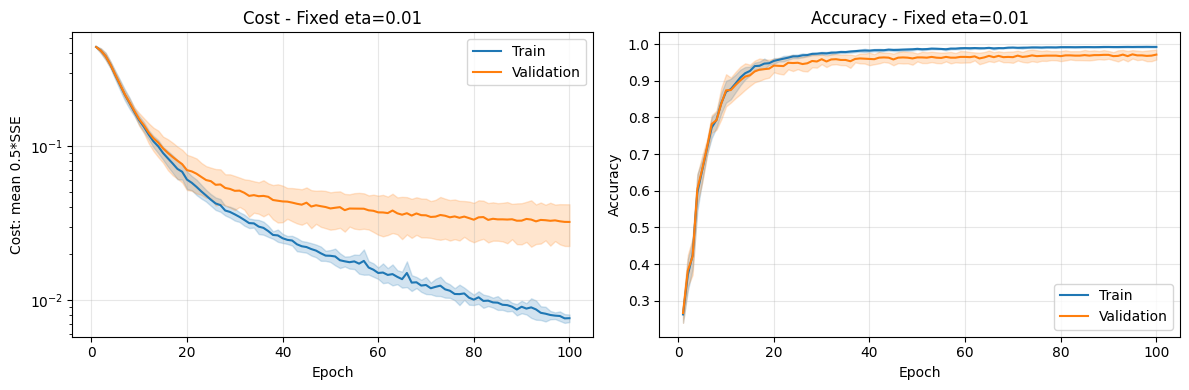

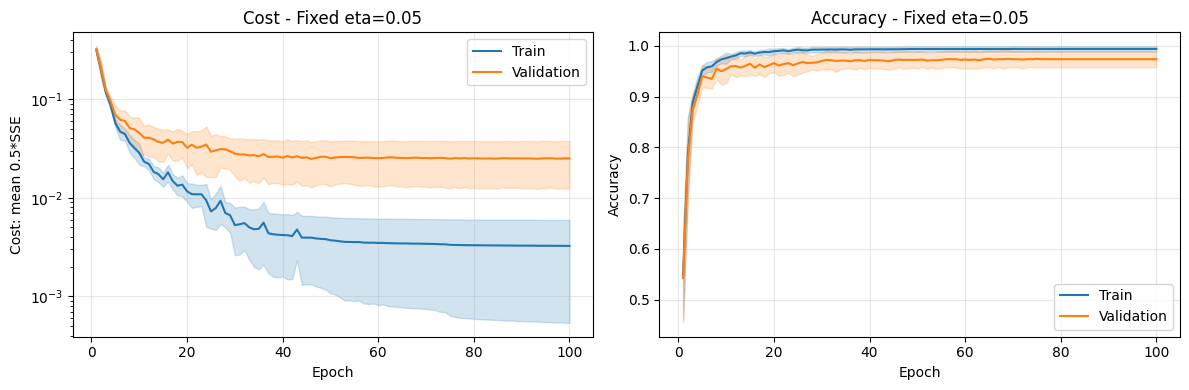

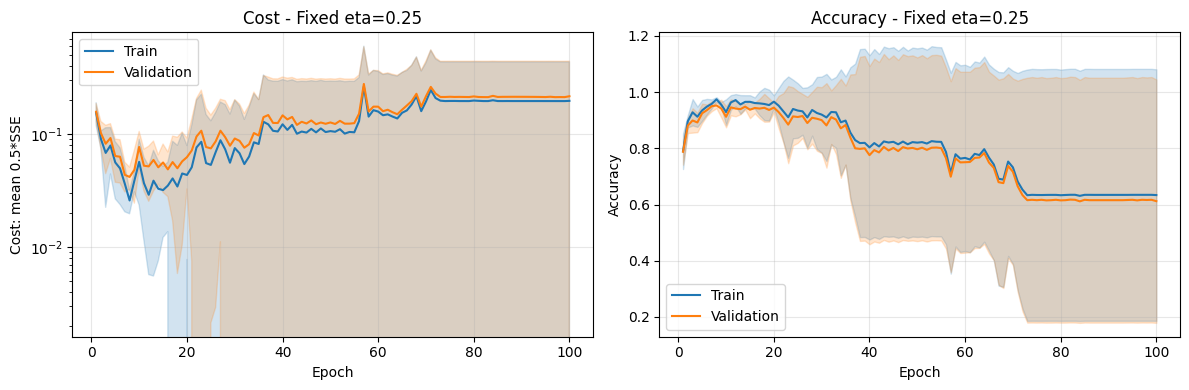

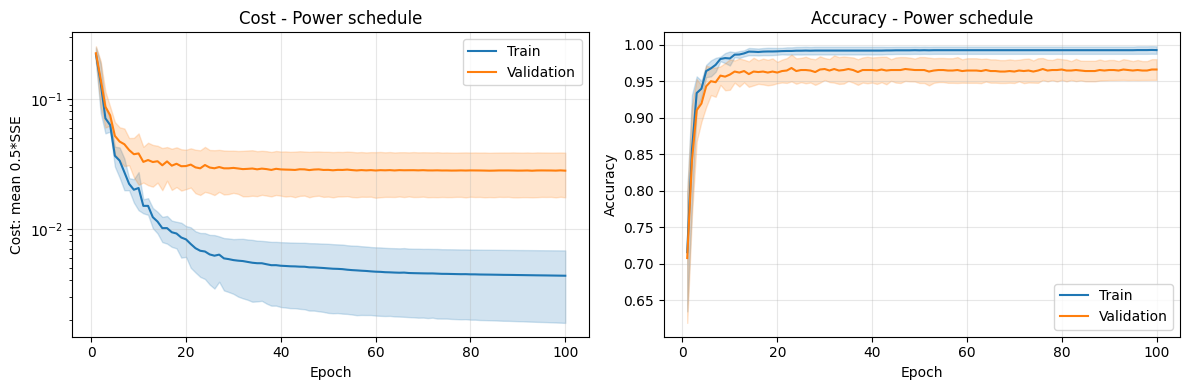

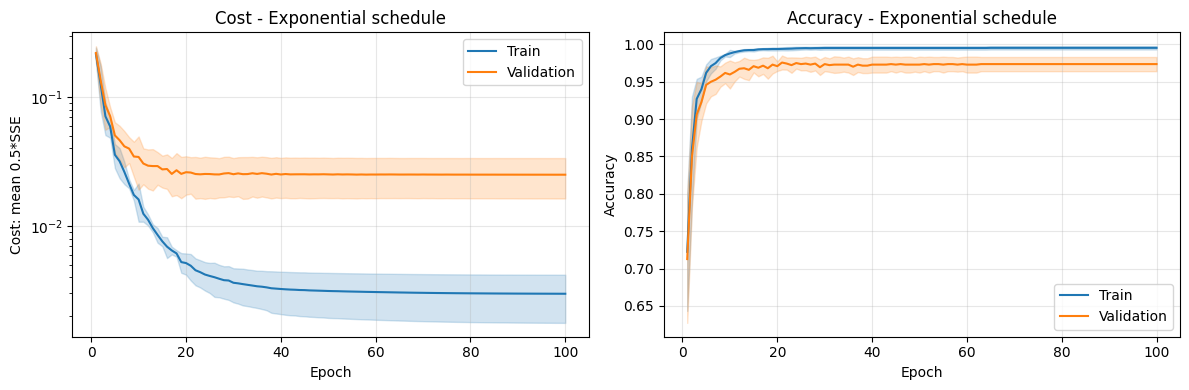

In [12]:
# (DO NOT MODIFY)
for r in results_sse:
    plot_cv_curves(r)

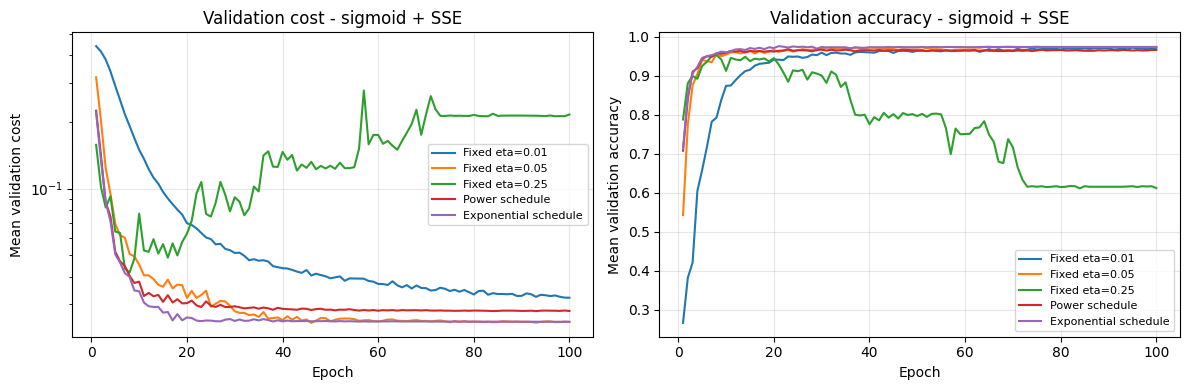


strategy                val cost (mean+/-std)     val acc (mean+/-std)        best epoch
----------------------------------------------------------------------------------------
Fixed eta=0.01          0.0314 +/- 0.0096         0.9708 +/- 0.0122                   97
Fixed eta=0.05          0.0240 +/- 0.0125         0.9749 +/- 0.0173                   46
Fixed eta=0.25          0.0219 +/- 0.0033         0.9763 +/- 0.0041                   29
Power schedule          0.0276 +/- 0.0105         0.9666 +/- 0.0126                   70
Exponential schedule    0.0240 +/- 0.0085         0.9750 +/- 0.0119                   22


In [13]:
# (DO NOT MODIFY)
plot_comparison(results_sse, "sigmoid + SSE")
print()
summarize(results_sse)

## 6. Part 3 — model evaluation

Three things happen here, in order:

1. **3(b)** — for *each* of the five strategies, the epoch of lowest mean validation cost and the
   epoch of highest mean validation accuracy.
2. **3(a)** — select one strategy using the mean cross-validated validation accuracy.
3. **3(c)–3(e)** — evaluate the five fold checkpoints of the selected strategy on the test set, and
   plot the confusion matrix summed over them.

In [14]:
# ============================================================
# Part 3(b) - per-strategy epochs (TODO)
# ============================================================
# TODO: for EACH of the five strategies in results_sse, print
#         - the epoch at which the fold-mean validation COST is lowest
#         - the epoch at which the fold-mean validation ACCURACY is highest
#       Use nanmean(r["val_cost"], axis=0) and nanmean(r["val_acc"], axis=0),
#       then np.nanargmin / np.nanargmax. Remember the curves are 0-indexed
#       but epochs are reported 1-indexed.
#
#       Print one row per strategy with both epochs side by side, so the
#       relationship asked about in the discussion is visible at a glance.
print(f"{'strategy':<24}{'epoch of min val cost':>24}{'epoch of max val acc':>24}")
print("-" * 72)

for r in results_sse:
    mean_cost = nanmean(r["val_cost"], axis=0)
    mean_acc  = nanmean(r["val_acc"],  axis=0)
    ep_cost = int(np.nanargmin(mean_cost)) + 1
    ep_acc  = int(np.nanargmax(mean_acc)) + 1
    print(f"{r['name']:<24}{ep_cost:>24}{ep_acc:>24}")

strategy                   epoch of min val cost    epoch of max val acc
------------------------------------------------------------------------
Fixed eta=0.01                               100                      95
Fixed eta=0.05                                46                      65
Fixed eta=0.25                                 8                       8
Power schedule                                93                      23
Exponential schedule                         100                      21


In [15]:
# ============================================================
# Part 3(a) - model selection (TODO)
# ============================================================
# Selection uses the mean cross-validated validation ACCURACY. peak_val_acc(r)
# is provided and returns (peak_accuracy, epoch_of_peak).
#
# TODO: rank the five strategies in results_sse by peak mean CV validation
#       accuracy, highest first, and print the ranking.
ranked = sorted(results_sse, key=lambda r: peak_val_acc(r)[0], reverse=True)
print("Ranking by peak mean CV validation accuracy:")
for rank, r in enumerate(ranked, 1):
    acc, ep = peak_val_acc(r)
    print(f"  {rank}. {r['name']:<24} {acc:.4f}  (epoch {ep})")


# TODO: set the four variables below.
#         overall      - the selected result dict from results_sse
#         final_epochs - epoch of peak mean validation accuracy
#         cv_acc       - the peak mean CV validation accuracy
#         cv_std       - std across the 5 folds of val_acc at that epoch
overall      = ranked[0]
cv_acc, final_epochs = peak_val_acc(overall)
cv_std       = float(nanstd(overall["val_acc"][:, final_epochs - 1]))

print(f"\nSelected: {overall['name']}")
print(f"  mean CV validation accuracy : {cv_acc:.4f} +/- {cv_std:.4f}")
print(f"  epoch of peak val accuracy  : {final_epochs}")

Ranking by peak mean CV validation accuracy:
  1. Exponential schedule     0.9756  (epoch 21)
  2. Fixed eta=0.05           0.9743  (epoch 65)
  3. Fixed eta=0.01           0.9722  (epoch 95)
  4. Power schedule           0.9680  (epoch 23)
  5. Fixed eta=0.25           0.9527  (epoch 8)

Selected: Exponential schedule
  mean CV validation accuracy : 0.9756 +/- 0.0093
  epoch of peak val accuracy  : 21


### Part 3(c)–3(d) — test evaluation

Cross-validation has already trained five models for the selected strategy, one per fold, and
`train_fold` restored each one's **checkpointed weights** (those at that fold's lowest validation
cost) before returning it. They are available as `overall["folds"][i]["model"]`.

Evaluate all five on the test set and report the mean and standard deviation. Do not retrain, and
do not pick a single fold — every fold model is used.

Note what the standard deviation does and does not capture; part 3 asks you to judge whether the
differences you see are meaningful.

In [16]:
# ============================================================
# Part 3(c)-3(d) - test evaluation of the five fold models (TODO)
# ============================================================
# TODO: for each of the five folds of `overall`, take its checkpointed model
#       (overall["folds"][i]["model"]) and compute its accuracy on the test set
#       with accuracy_score. Collect them into test_accs.
test_accs = np.array([accuracy_score(y_test, f["model"].predict(X_test))
                      for f in overall["folds"]])

# TODO: print one line per fold showing that fold's validation accuracy
#       (overall["folds"][i]["best_val_acc"]) next to its test accuracy.
for i, f in enumerate(overall["folds"]):
    print(f"Fold {i + 1}: val acc {f['best_val_acc']:.4f}   test acc {test_accs[i]:.4f}")



print(f"\nTest accuracy over the 5 fold models: "
      f"{np.mean(test_accs):.4f} +/- {np.std(test_accs):.4f}")
print(f"CV validation accuracy               : {cv_acc:.4f} +/- {cv_std:.4f}")

Fold 1: val acc 0.9653   test acc 0.9444
Fold 2: val acc 0.9757   test acc 0.9722
Fold 3: val acc 0.9861   test acc 0.9778
Fold 4: val acc 0.9582   test acc 0.9583
Fold 5: val acc 0.9895   test acc 0.9806

Test accuracy over the 5 fold models: 0.9667 +/- 0.0135
CV validation accuracy               : 0.9756 +/- 0.0093


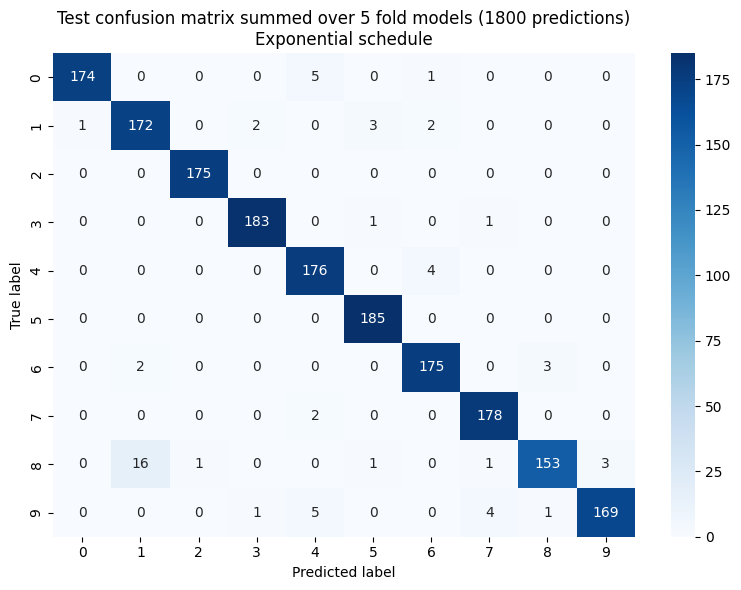

Most frequent confusions (true -> predicted : count)
  8 -> 1 : 16
  0 -> 4 : 5
  9 -> 4 : 5
  4 -> 6 : 4
  9 -> 7 : 4
  1 -> 5 : 3
  6 -> 8 : 3
  8 -> 9 : 3
  1 -> 3 : 2
  1 -> 6 : 2
  6 -> 1 : 2
  7 -> 4 : 2
  0 -> 6 : 1
  1 -> 0 : 1
  3 -> 5 : 1
  3 -> 7 : 1
  8 -> 2 : 1
  8 -> 5 : 1
  8 -> 7 : 1
  9 -> 3 : 1
  9 -> 8 : 1


In [17]:
# ============================================================
# Part 3(e) - Confusion Matrix (TODO)
# ============================================================
# TODO: build ONE confusion matrix summed over the five fold models: compute
#       each fold model's confusion matrix on the test set with
#       confusion_matrix(..., labels=range(N_CLASSES)) and add them elementwise.
#       The result covers 5 x 360 = 1800 predictions.
cm = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for f in overall["folds"]:
    cm += confusion_matrix(y_test, f["model"].predict(X_test), labels=range(N_CLASSES))

# TODO: plot cm as a seaborn heatmap with integer annotations, labelled axes
#       and a title.
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(N_CLASSES), yticklabels=range(N_CLASSES))
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Test confusion matrix summed over 5 fold models ({cm.sum()} predictions)\n{overall['name']}")
plt.tight_layout(); plt.show()


# TODO: print the most frequent off-diagonal confusions as
#       "true -> predicted : count", sorted by count descending.
off_diag = [(cm[i, j], i, j) for i in range(N_CLASSES) for j in range(N_CLASSES)
            if i != j and cm[i, j] > 0]
off_diag.sort(key=lambda t: t[0], reverse=True)
print("Most frequent confusions (true -> predicted : count)")
for count, i, j in off_diag:
    print(f"  {i} -> {j} : {count}")

## 7. Part 4 — softmax output with cross-entropy

Same hidden layers, same training loop, different output layer. Part 4(a) asks you to derive the
output-layer error term for this combination before you implement it — do the derivation first and
use your own result in `backward`.

Only the **best strategy identified in part 3** is used here, over the same five folds, and the
five checkpoints are evaluated on the test set exactly as in part 3.

### Part 4(a) — derivation

**Setup.** For one sample, the output layer has induced local fields $v_k = \sum_j w_{jk}\, y^{(2)}_j + b_k$, outputs $y_k$, and desired outputs $d_k$ (one-hot, so $\sum_k d_k = 1$). Averaging over $N$ samples only adds a factor $1/N$, so the single-sample case is shown.

**1. Softmax + cross-entropy: $\partial J/\partial v_k$**

$$y_k = \frac{e^{v_k}}{\sum_{j=1}^{10} e^{v_j}}, \qquad J = -\sum_{m=1}^{10} d_m \log y_m$$

Softmax Jacobian (each $y_m$ depends on every $v_k$ through the denominator):

$$\frac{\partial y_m}{\partial v_k} = y_m(\delta_{mk} - y_k)$$

Chain rule over all outputs:

$$\frac{\partial J}{\partial v_k} = \sum_{m} \frac{\partial J}{\partial y_m}\frac{\partial y_m}{\partial v_k}
= \sum_m \left(-\frac{d_m}{y_m}\right) y_m(\delta_{mk} - y_k)
= -\sum_m d_m(\delta_{mk} - y_k)
= -d_k + y_k\sum_m d_m$$

Since $\sum_m d_m = 1$:

$$\boxed{\;\delta^{(3)}_k = \frac{\partial J}{\partial v_k} = y_k - d_k\;}$$

**2. Gradient for the output-layer weights**

$$\frac{\partial J}{\partial w_{jk}} = \frac{\partial J}{\partial v_k}\frac{\partial v_k}{\partial w_{jk}} = (y_k - d_k)\, y^{(2)}_j,
\qquad \frac{\partial J}{\partial b_k} = y_k - d_k$$

Over $N$ samples, in matrix form: $\nabla_{W^{(3)}} J = \frac{1}{N}\, (Y^{(2)})^{\top}(Y - D)$. The SGD update is $w_{jk} \leftarrow w_{jk} - \eta\,(y_k - d_k)\,y^{(2)}_j$.

**3. Sigmoid + scaled SSE, for comparison**

$$y_k = \sigma(v_k),\quad J = \tfrac12\sum_k (d_k - y_k)^2,\quad \sigma'(v_k) = y_k(1-y_k)$$

$$\boxed{\;\delta^{(3)}_k = \frac{\partial J}{\partial v_k} = -(d_k - y_k)\,\sigma'(v_k) = (y_k - d_k)\, y_k(1 - y_k)\;}$$

$$\frac{\partial J}{\partial w_{jk}} = (y_k - d_k)\, y_k(1-y_k)\, y^{(2)}_j$$

**4. Difference between the two expession**

The two error terms differ only by the factor $y_k(1-y_k) = \sigma'(v_k)$, which is at most 0.25 and goes to 0 when the output saturates near 0 or 1. With sigmoid + SSE, a confidently wrong output (e.g. $d_k = 1$, $y_k \approx 0$) therefore gets almost no gradient, so learning slows exactly where correction is needed. With softmax + cross-entropy, the $1/y_k$ from the log cancels this factor, so the error term is simply $y_k - d_k$, proportional to how wrong the output is.


In [18]:
# ============================================================
# Part 4(b)-4(c) - softmax network at the selected strategy (TODO)
# ============================================================
# TODO: run run_cv() once, with mode="softmax_ce" and the learning rate
#       strategy selected in part 3 (overall["name"]). Store it in result_ce.
#       Print the same per-configuration summary line as in section 5:
#       mean best validation cost, mean best validation accuracy, and the
#       median best epoch.
strategy_fns = dict(STRATEGIES)
result_ce = run_cv(overall["name"], strategy_fns[overall["name"]], mode="softmax_ce")

n_div = sum(d is not None for d in result_ce["diverged"])
note = f"   <- diverged in {n_div}/{N_FOLDS} folds" if n_div else ""
print(f"{result_ce['name']:<24} val cost {nanmean(result_ce['best_val_costs']):.4f}  "
      f"val acc {nanmean(result_ce['best_val_accs']):.4f}  "
      f"median best epoch {int(np.nanmedian(result_ce['best_epochs']))}{note}")

Exponential schedule     val cost 0.1433  val acc 0.9722  median best epoch 19


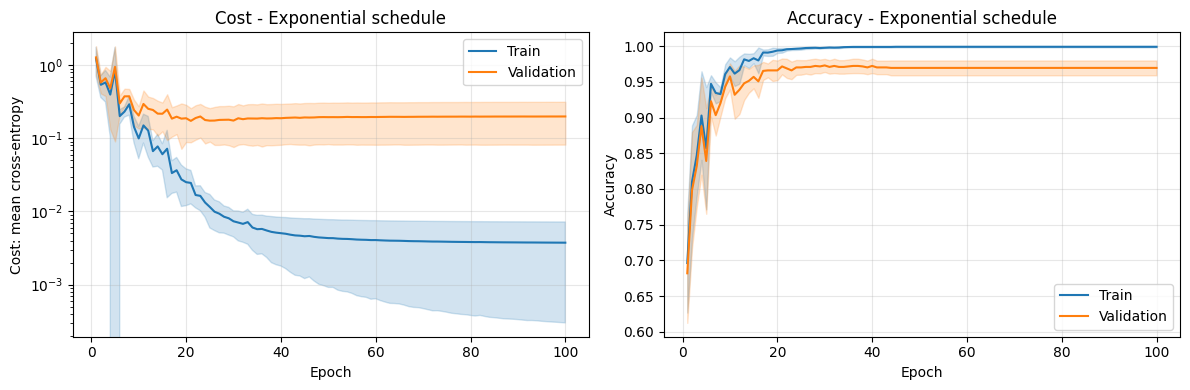


strategy                val cost (mean+/-std)     val acc (mean+/-std)        best epoch
----------------------------------------------------------------------------------------
Exponential schedule    0.1433 +/- 0.0808         0.9722 +/- 0.0123                   19


In [19]:
# (DO NOT MODIFY) Learning curves for the softmax configuration
plot_cv_curves(result_ce)
print()
summarize([result_ce])

In [20]:
# ============================================================
# Part 4 - softmax: epochs and test evaluation (TODO)
# ============================================================
# The same protocol as part 3, on the same five folds, so the two output
# layers are compared on identical splits.
#
# TODO: print the epoch of lowest mean validation cost and the epoch of highest
#       mean validation accuracy for result_ce, as in Part 3(b).
ce_ep_cost = int(np.nanargmin(nanmean(result_ce["val_cost"], axis=0))) + 1
ce_ep_acc  = int(np.nanargmax(nanmean(result_ce["val_acc"],  axis=0))) + 1
print(f"{'strategy':<24}{'epoch of min val cost':>24}{'epoch of max val acc':>24}")
print("-" * 72)
print(f"{result_ce['name']:<24}{ce_ep_cost:>24}{ce_ep_acc:>24}")


# TODO: set ce_cv_acc and ce_cv_std from result_ce, the same way cv_acc and
#       cv_std were set in Part 3(a).
ce_cv_acc, ce_final_epochs = peak_val_acc(result_ce)
ce_cv_std = float(nanstd(result_ce["val_acc"][:, ce_final_epochs - 1]))
print(f"\nSoftmax mean CV validation accuracy : {ce_cv_acc:.4f} +/- {ce_cv_std:.4f} "
      f"(epoch {ce_final_epochs})\n")

# TODO: evaluate the five softmax fold checkpoints on the test set and collect
#       the accuracies into ce_test_accs. Print one line per fold, as in part 3.
ce_test_accs = np.array([accuracy_score(y_test, f["model"].predict(X_test))
                         for f in result_ce["folds"]])
for i, f in enumerate(result_ce["folds"]):
    print(f"Fold {i + 1}: val acc {f['best_val_acc']:.4f}   test acc {ce_test_accs[i]:.4f}")


print(f"\nSoftmax test accuracy over the 5 fold models: "
      f"{np.mean(ce_test_accs):.4f} +/- {np.std(ce_test_accs):.4f}")
print(f"Sigmoid test accuracy over the 5 fold models: "
      f"{np.mean(test_accs):.4f} +/- {np.std(test_accs):.4f}")

strategy                   epoch of min val cost    epoch of max val acc
------------------------------------------------------------------------
Exponential schedule                          21                      30

Softmax mean CV validation accuracy : 0.9729 +/- 0.0092 (epoch 30)

Fold 1: val acc 0.9826   test acc 0.9556
Fold 2: val acc 0.9653   test acc 0.9556
Fold 3: val acc 0.9826   test acc 0.9694
Fold 4: val acc 0.9512   test acc 0.9694
Fold 5: val acc 0.9791   test acc 0.9583

Softmax test accuracy over the 5 fold models: 0.9617 +/- 0.0064
Sigmoid test accuracy over the 5 fold models: 0.9667 +/- 0.0135


## 8. Written Discussion (REQUIRED)

Failure to include this discussion will result in point deductions. Answer each item in a markdown
cell below, referring to your own plots and printed numbers.

**Part 1 — fixed learning rates.** Discuss how η = 0.01, 0.05 and 0.25 each influence convergence.
Analyze the learning curves for the training and validation sets, note any patterns or differences,
and state what evidence in the curves supports your conclusions.

**Part 2 — schedules.** Report the η values printed by the schedule cell at n = 0, n = s and
n = n_total. Compare both schedules against each other and against the three fixed rates, and
discuss their effect on convergence and on the learning curves.

**Part 3(a) — selection criterion.** Which is the better selection criterion, validation accuracy or
validation cost? Justify your answer.

**Part 3(b) — epochs.** Discuss the relationship between the epoch of lowest validation cost and the
epoch of highest validation accuracy, using the per-strategy table you printed.

**Part 3(e) — confusion matrix.** Which digit pairs account for most of the remaining errors, and
why are those particular pairs confused?

**Part 3 — generalization.** Compare training, cross-validated validation, and test results. Are the
differences large enough to be meaningful, given the size of the test set?

**Part 4(a) — derivation.** (Answered in the derivation cell above.)

**Part 4(d) — output layers.** Compare the two output layers on speed of convergence and on
sensitivity to the choice of learning rate. Relate what you observe to the expressions you derived
in part 4(a).

## Part 1 — Fixed learning rates

- **η = 0.01 (too small):** I found that η = 0.01 is too slow for convergence. The median best epoch is 97 of 100, so the validation cost was still falling when training stopped and the network never fully converged. Evidence: the curves are still sloping down at epoch 100, they are smooth with a narrow ±1 std band, and the gap between training and validation is small. Best validation accuracy: 0.9708.
- **η = 0.05 (balanced):** I found that η = 0.05 converges in a reasonable number of epochs (median best epoch 46) and gives the highest peak mean validation accuracy of the three fixed rates (0.9743). After about epoch 46 the validation cost flattens while the training cost keeps falling. This shows the start of overfitting, which is why the checkpoint at the lowest validation cost is kept.
- **η = 0.25 (too large):** I found that η = 0.25 converges fastest at first but is unstable. The mean validation curves reach their best point at epoch 8 (peak mean validation accuracy 0.9527), and the individual folds' best checkpoints (median epoch 29) reach 0.9763 ± 0.0041. After about epoch 30, however, the mean validation cost rises sharply with large spikes and the mean validation accuracy falls to about 0.62 by the end. No fold produced non-finite weights, so this is not numerical divergence: the large per-sample steps push some folds into a bad state they cannot recover from (for example, ReLU units that stop activating). The checkpointing hides this in the summary table, but the curves show that η = 0.25 is too large for stable training.

**Conclusion:** A larger η speeds up convergence but makes training unstable. η = 0.25 reaches a good checkpoint early and then collapses, while η = 0.01 is stable but too slow to converge in 100 epochs. η = 0.05 gives the best balance of speed and stability.

## Part 2 — Learning rate schedules

| n | Power | Exponential |
|---|---|---|
| 0 | 0.10000 | 0.1000 |
| s | 0.05000 (s = 11500) | 0.0100 (s = 57500) |
| n_total = 115000 | 0.00909 | 0.0010 |

Both schedules start at η = 0.1, so they make fast progress early like a large fixed rate, then reduce η so later updates are small and stable.

- **Exponential schedule:** best overall. Highest peak mean validation accuracy (0.9756 at epoch 21; best-checkpoint accuracy 0.9750 ± 0.0119). It keeps η large for longer at the start, then shrinks it to 0.001 by the end, so the final epochs make only tiny changes. Its curves are smooth and flatten out near the end, and the validation cost keeps improving slightly until epoch 100 instead of rising.
- **Power schedule:** the weaker schedule. It has the lowest best-checkpoint accuracy of all five strategies (0.9666), and its peak mean validation accuracy (0.9680) is below every strategy except η = 0.25. η halves within the first 10 epochs (by n = 11500), so it loses the benefit of a large step early. It then decays slowly and ends at about 0.009, close to the fixed η = 0.01, so it behaves like a slow fixed rate after the first few epochs.
- **Compared with fixed rates:** the exponential schedule gets the speed of a large rate early and the stability of a small rate late. It avoids the collapse seen with η = 0.25 and the slow convergence of η = 0.01, and it slightly beats the best fixed rate on peak mean validation accuracy (0.9756 vs 0.9743 for η = 0.05).

## Part 3(a) — Validation accuracy vs validation cost

Validation accuracy is the better criterion for selecting the final model, because correct classification is the actual goal of this task. Validation cost measures how close the outputs are to their targets, which reflects confidence rather than correctness. The cost can keep falling simply because already-correct predictions become more confident, even when no extra samples are classified correctly.

My results show the two criteria can point to very different epochs. For the power schedule, the lowest validation cost is at epoch 93 but the highest validation accuracy is at epoch 23. For the exponential schedule, they are at epochs 100 and 21. Selecting by cost would favor late epochs that do not give the best accuracy.

Accuracy is coarser than cost (one validation sample changes it by about 0.35%), so cost remains useful for checkpointing weights during training. For choosing the final strategy, however, accuracy measures what matters.

Therefore, validation accuracy is the better selection criterion for this task.

## Part 3(b) — Epoch of lowest validation cost vs highest validation accuracy

| Strategy | Min val cost | Max val acc |
|---|---|---|
| Fixed η = 0.01 | 100 | 95 |
| Fixed η = 0.05 | 46 | 65 |
| Fixed η = 0.25 | 8 | 8 |
| Power schedule | 93 | 23 |
| Exponential schedule | 100 | 21 |

The two epochs are generally not the same. They only match for η = 0.25, where the model reaches its best point very early (epoch 8) and then gets worse.

For the schedules, accuracy peaks early (about epoch 21–23) but cost keeps going down until near the end. Once η is small, the network does not change which class it predicts, but it keeps pushing correct outputs closer to their targets, which lowers the cost without changing accuracy. For η = 0.05 the order is reversed (cost at 46, accuracy at 65): the cost starts to rise from a few confidently wrong samples while accuracy still improves slightly.

So the lowest cost and the highest accuracy measure different things (confidence vs correct class) and should not be assumed to happen at the same epoch.

## Part 3(e) — Confusion matrix

Across the 1800 test predictions there are 60 errors. The largest by far is 8 predicted as 1 (16 times), about a quarter of all mistakes. Next are 0 → 4 (5 times), 9 → 4 (5 times), 4 → 6 (4 times) and 9 → 7 (4 times).

Why these pairs:
- **8 → 1:** At 8×8 resolution, a narrow or thinly written 8 loses its two loops and collapses into a mostly vertical stroke down the middle columns, which looks like a 1.
- **9 → 4 and 9 → 7:** A 9 has a loop on top and a vertical stroke on the right. A 4 with a closed top has the same shape, and a 9 with a small or flat loop looks like a 7.
- **4 → 6 and 0 → 4:** Open or unevenly drawn loops get blurred at low resolution and can match the pixel pattern of another digit.

All of these pairs share most of their active pixels, and at 64 pixels the small details that separate them are lost.

## Part 3 — Training vs validation vs test

For the selected strategy (exponential schedule):
- Training accuracy: close to 100% by the end of training (from the learning curves)
- Cross-validated validation accuracy: 0.9756 ± 0.0093
- Test accuracy over the 5 fold models: 0.9667 ± 0.0135

Training accuracy is clearly higher than validation and test, so the model fits the training data better than unseen data, which is normal. The final training cost (about 0.003) is also roughly 8× lower than the validation cost (about 0.025).

The gap between validation and test is only about 0.009, which is about 3 test samples out of 360. The standard error of a test accuracy near 0.967 with 360 samples is sqrt(0.967 × 0.033 / 360) ≈ 0.0095, so the gap is about one standard error. That is not large enough to be meaningful. It is also smaller than the fold-to-fold spread of the test accuracy (0.0135).

The small drop is also expected because the validation accuracy is slightly optimistic: it was used to choose both the strategy (best of five) and the epoch, so it has a small selection bias. The test set was never used for any choice, so it gives an unbiased estimate.

Note: the ±0.0135 only captures variation between the five trained models. All five are tested on the same 360 samples, so it does not capture the uncertainty from the small test set itself.

## Part 4(d) — Sigmoid + SSE vs softmax + cross-entropy

Results with the exponential schedule on the same 5 folds:

| | CV val accuracy | Test accuracy | Epoch of min val cost | Epoch of max val acc |
|---|---|---|---|---|
| Sigmoid + SSE | 0.9756 ± 0.0093 | 0.9667 ± 0.0135 | 100 | 21 |
| Softmax + CE | 0.9729 ± 0.0092 | 0.9617 ± 0.0064 | 21 | 30 |

**Derivation.** From part 4(a), the softmax error term is δ = y − d, while the sigmoid error term is δ = (y − d)·y(1 − y). The factor y(1 − y) is at most 0.25, so for the same η, softmax takes steps at least 4× larger and is never slowed by saturated outputs.

**Speed of convergence.** In theory this makes softmax learn faster, but with this schedule it did not. Its validation accuracy curve jumps up and down in the first 10 epochs and only settles near 0.97 after about epoch 20, while sigmoid's curve rises more smoothly. With η starting at 0.1, the larger softmax gradients make each per-sample step overshoot.

**Sensitivity to the learning rate.** The exponential schedule was selected for sigmoid. Because the softmax gradient is not scaled down by y(1 − y), the same η acts as a much larger effective step, so softmax is more sensitive to the choice of η. This also shows in the epoch table. For sigmoid, validation cost keeps decreasing until epoch 100. For softmax, validation cost reaches its minimum at epoch 21 and then rises, even though accuracy keeps improving until epoch 30, and the training cost keeps falling to about 0.004. Cross-entropy heavily penalizes the few predictions that become confidently wrong, so the validation cost turns upward while most predictions are still improving. Sigmoid + SSE is more forgiving because y(1 − y) shrinks the step. Softmax would likely do better with a smaller η.

**Conclusion.** Only one strategy was tested for softmax, so its sensitivity is inferred from the derivation and the curves, not measured across rates. The two output layers reach similar accuracy: the test accuracies differ by 0.005 (about 2 of 360 test samples), which is within one standard error, so neither is clearly better on this test set.